In [1]:
import sys
import os
import random
from pathlib import Path

import torch
from torch import optim
import torchvision
import numpy as np
from tqdm import tqdm
import matplotlib.pyplot as plt

In [2]:
project_root = Path.cwd().parent 
sys.path.append(str(project_root))

In [3]:
from img_generation.datasets import Config, DatasetType, load_dataloaders, VAE_TRANSFORM_MONO
from img_generation.models.vae import VQVAE, vqvae_loss, train_vq_vae, NUM_EMBEDDINGS
from img_generation.utils import EarlyStopping


In [4]:
def set_seed(seed):
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.use_deterministic_algorithms(True)

if torch.cuda.is_available():
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(SEED)

# os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"  # wymagane przez niektóre operacje CUDA
device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.mps.is_available() else "cpu")
device

device(type='mps')

In [5]:
config = Config(dataset_type=DatasetType.FASHION_MNIST, data_dir="../data/fashion_mnist", model_type="vae", batch_size=128, num_workers=4)
dataloaders, classes = load_dataloaders(config=config, transform=VAE_TRANSFORM_MONO)

print(f"All classes: {classes}")
print(f"Number of all classes: {len(classes)}")

Loaded train dataset: 54000 images, 10 classes.
All classes: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
Number of all classes: 10


In [6]:
for x, y in dataloaders["train"]:
    print(f"Input img shape: {x.shape}")
    print(f"class: {y}")
    break

/Users/kwasus/Desktop/STUDIA/SEM6/LLM/PROJECT/Autoregressive-Image-Generation/.venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:1095: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Input img shape: torch.Size([128, 1, 28, 28])
class: tensor([8, 0, 4, 9, 0, 9, 7, 5, 6, 8, 2, 5, 0, 6, 1, 9, 1, 1, 6, 9, 1, 0, 9, 2,
        5, 5, 4, 0, 9, 5, 3, 5, 9, 2, 4, 5, 6, 9, 0, 8, 0, 6, 5, 6, 1, 3, 9, 0,
        6, 8, 8, 8, 0, 8, 5, 0, 5, 8, 8, 2, 7, 0, 9, 3, 5, 6, 4, 4, 5, 8, 2, 7,
        8, 2, 6, 8, 3, 2, 0, 0, 6, 2, 5, 4, 1, 1, 6, 3, 0, 1, 9, 6, 2, 3, 8, 1,
        1, 0, 0, 5, 2, 3, 6, 1, 5, 5, 9, 7, 6, 7, 3, 9, 8, 9, 9, 1, 3, 3, 5, 2,
        7, 2, 6, 1, 8, 1, 9, 4])


In [7]:
for x, _ in dataloaders["train"]:
    input_channels, input_size = x.shape[1], x.shape[2] # (B, C, H, W)
    break

In [8]:
hidden_dim = 32
num_embeddings = NUM_EMBEDDINGS
# ^^Number of vectors in the codebook

vq_vae = VQVAE(in_channels=input_channels, hidden_dim=hidden_dim, num_embeddings=num_embeddings).to(device)
optimizer = optim.Adam(vq_vae.parameters(), lr=0.001)
scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer=optimizer, gamma=0.99)
early_stopping = EarlyStopping(patience=10, delta = 0.01)

100%|██████████| 421/421 [00:07<00:00, 53.23it/s]


(Epoch 1/[train]) -> Total Loss:	1.491 -> lr: 0.001


100%|██████████| 47/47 [00:02<00:00, 20.95it/s]


(Epoch 1/[val]) -> Total Loss:	1.063 -> lr: 0.001


100%|██████████| 421/421 [00:06<00:00, 61.88it/s]


...

(Epoch 9/[val]) -> Total Loss:	0.650 -> lr: 0.00092274469442792


100%|██████████| 421/421 [00:06<00:00, 67.62it/s]


(Epoch 10/[train]) -> Total Loss:	0.653 -> lr: 0.0009135172474836408


100%|██████████| 47/47 [00:01<00:00, 24.00it/s]
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..1.0].


(Epoch 10/[val]) -> Total Loss:	0.650 -> lr: 0.0009135172474836408


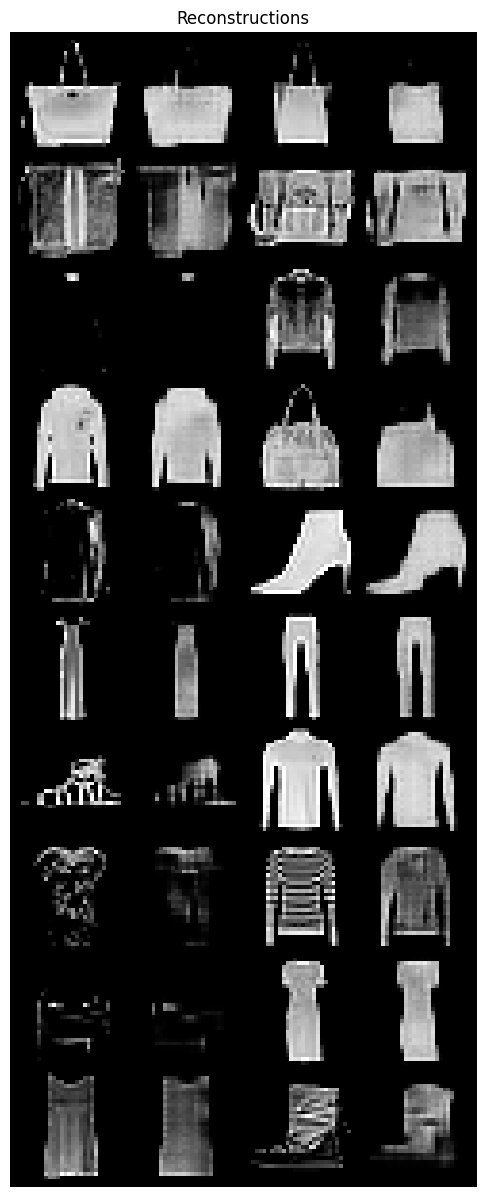

100%|██████████| 421/421 [00:06<00:00, 68.55it/s]


(Epoch 11/[train]) -> Total Loss:	0.652 -> lr: 0.0009043820750088043


100%|██████████| 47/47 [00:01<00:00, 24.12it/s]


(Epoch 11/[val]) -> Total Loss:	0.650 -> lr: 0.0009043820750088043


100%|██████████| 421/421 [00:06<00:00, 63.39it/s]


...

(Epoch 18/[val]) -> Total Loss:	0.641 -> lr: 0.0008429431933839266


100%|██████████| 421/421 [00:06<00:00, 67.45it/s]


(Epoch 19/[train]) -> Total Loss:	0.644 -> lr: 0.0008345137614500873


100%|██████████| 47/47 [00:01<00:00, 24.20it/s]

(Epoch 19/[val]) -> Total Loss:	0.641 -> lr: 0.0008345137614500873
Early stopping


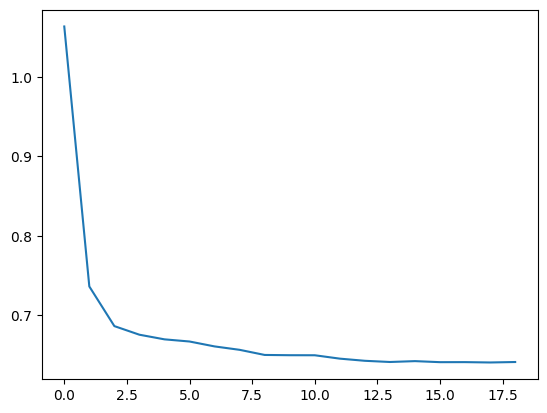

In [9]:
epochs = 70

early_stopping, val_lossses = train_vq_vae(model=vq_vae, loaders=dataloaders, criterion=vqvae_loss, optimizer=optimizer, lr_scheduler=scheduler, 
                                early_stopping=early_stopping, num_epochs=epochs, device=device)
early_stopping.load_best_model(vq_vae)

plt.plot(val_lossses)

In [10]:
model_path = "../pretrained_models/vae"

torch.save(vq_vae.state_dict(), f=os.path.join(model_path, "vq_vae.pth"))

In [11]:
def visualize_reconstructions(model, input_imgs, device):
    # Reconstruct images
    model.eval()
    with torch.no_grad():
        reconst_imgs, _ = model(input_imgs.to(device))
    reconst_imgs = reconst_imgs.cpu()
    
    # Plotting
    imgs = torch.stack([input_imgs, reconst_imgs], dim=1).flatten(0,1)
    grid = torchvision.utils.make_grid(imgs, nrow=6, normalize=False)
    grid = grid.permute(1, 2, 0)
    if len(input_imgs) == 6:
        plt.figure(figsize=(15,10))
    else:
        plt.figure(figsize=(15,15))
    plt.title("Reconstructions")
    plt.imshow(grid)
    plt.axis('off')
    plt.show()

In [12]:
vq_vae.eval()
with torch.inference_mode():    
    test_losses = []
    for x, _ in tqdm(dataloaders["test"]):
        x = x.to(device)
        x_hat, loss = vq_vae(x)
        total_loss = vqvae_loss(x_hat, x, loss)
        test_losses.append(total_loss.item())
    print(f"Mean test loss: {np.mean(np.array(test_losses))}")

100%|██████████| 79/79 [00:02<00:00, 32.71it/s]

Mean test loss: 0.6428538832483413


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..1.0].


torch.Size([27, 1, 28, 28])


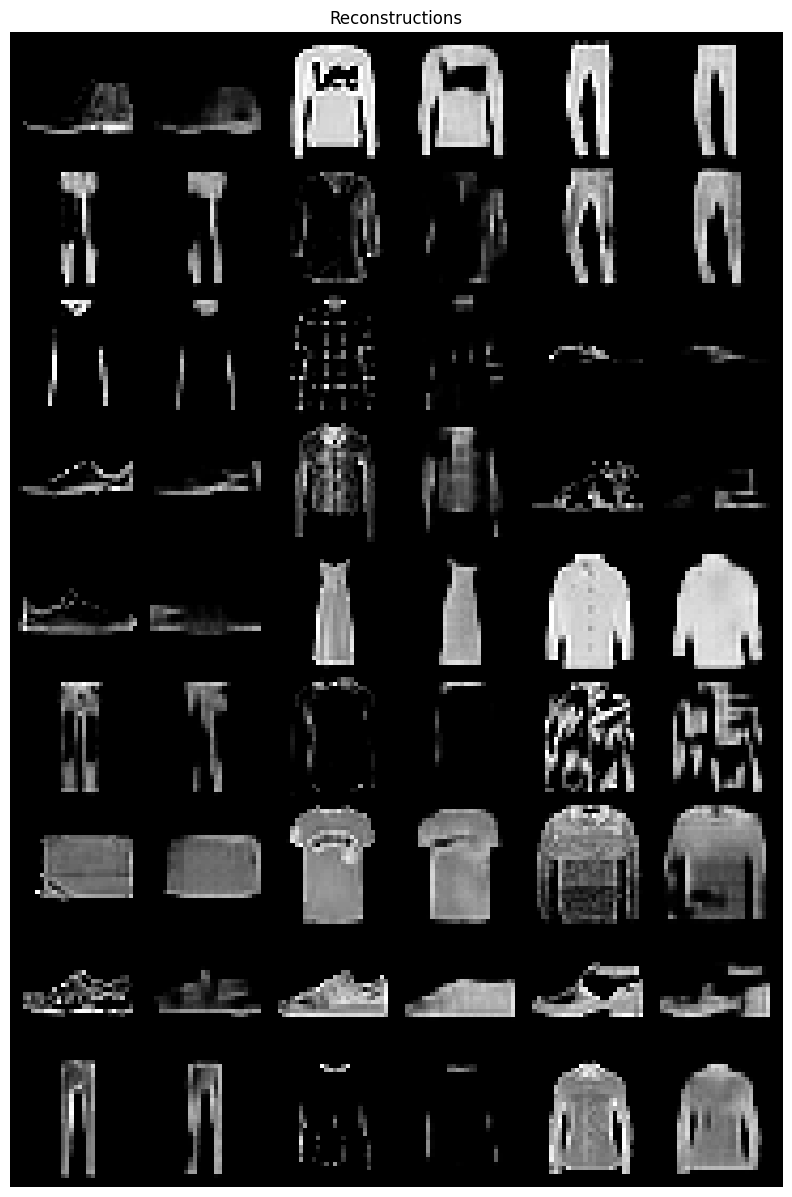

In [13]:
n_samples = 27
sample_imgs = torch.stack([dataloaders["test"].dataset[i][0] for i in range(n_samples)], dim=0)    # wraps all tensors in one one external tensor - [[..], [..], .., [..]]
print(sample_imgs.shape)
visualize_reconstructions(vq_vae, input_imgs=sample_imgs, device=device)